<a href="https://colab.research.google.com/github/kangyeson/AI-Class/blob/main/1026/car_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
# 구글 드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [55]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim

sns.set_theme(style="whitegrid")

# 1. 데이터 구조 확인

In [57]:
# 데이터 불러오기 (car.data에는 열 이름이 없으므로 직접 지정)
column_names = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/car.data", names=column_names)

print("데이터 크기:", df.shape)

print("\n처음 5개 데이터")
display(df.head())

print("\n데이터 정보")
df.info()

데이터 크기: (1728, 7)

처음 5개 데이터


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc



데이터 정보
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


**확인 결과**: 1,728행 × 7열, 7개 변수 모두 문자(object)형 → 모델에 넣으려면 숫자로 바꿔야 함

# 2. 결측치와 중복 데이터 확인

In [58]:
print("변수별 결측치 개수")
print(df.isnull().sum())

print("\n중복 행 개수")
print(df.duplicated().sum())

변수별 결측치 개수
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

중복 행 개수
0


**확인 결과**: 모든 변수의 결측치 0개, 중복 행 0개 → 별도 처리 필요 없음

# 3. 변수별 값 종류와 개수 확인

In [59]:
for col in column_names:
    print(f"\n[{col}]")
    print(df[col].value_counts())


[buying]
buying
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64

[maint]
maint
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64

[doors]
doors
2        432
3        432
4        432
5more    432
Name: count, dtype: int64

[persons]
persons
2       576
4       576
more    576
Name: count, dtype: int64

[lug_boot]
lug_boot
small    576
med      576
big      576
Name: count, dtype: int64

[safety]
safety
low     576
med     576
high    576
Name: count, dtype: int64

[class]
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


**확인 결과**
- 입력 변수 6개는 값마다 개수가 똑같음 (432개 또는 576개)
- 1,728 = 4 × 4 × 4 × 3 × 3 × 3 → 가능한 모든 조합이 정확히 한 번씩 들어 있는 데이터

# 4. 레이블(class) 개수 확인

In [60]:
print("레이블 종류")
print(df['class'].unique())

print("\n레이블별 개수")
print(df['class'].value_counts())

print("\n레이블별 비율(%)")
print((df['class'].value_counts(normalize=True) * 100).round(2))

레이블 종류
['unacc' 'acc' 'vgood' 'good']

레이블별 개수
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

레이블별 비율(%)
class
unacc    70.02
acc      22.22
good      3.99
vgood     3.76
Name: proportion, dtype: float64


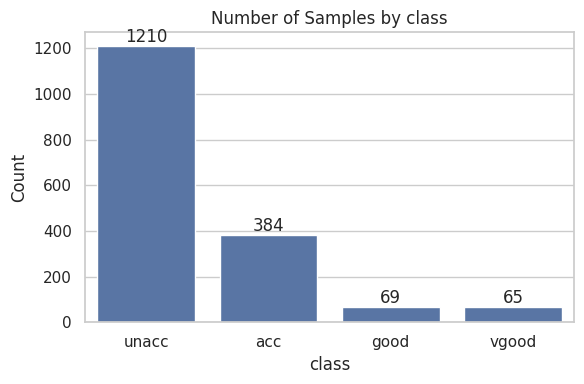

In [61]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    data=df,
    x='class',
    order=['unacc', 'acc', 'good', 'vgood']
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Samples by class")
plt.xlabel("class")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

**확인 결과**
- 레이블 종류: unacc, acc, good, vgood (4개)
- unacc 1,210개(70%), acc 384개(22%), good 69개(4%), vgood 65개(4%) → **클래스 불균형이 심함**
- 비어있는 클래스는 없지만, good과 vgood은 데이터가 매우 적음 → 이 두 등급은 맞히기 어려울 수 있음

# 5. 범주형 → 숫자 변환
크기 순서가 있는 값들이므로, 작은 것부터 0, 1, 2, ... 순서대로 숫자를 매긴다.
(LabelEncoder는 알파벳 순서로 번호를 매겨 high=0, low=1처럼 크기 순서가 뒤섞이므로 사용하지 않음)

In [62]:
price_dict = {'low': 0, 'med': 1, 'high': 2, 'vhigh': 3}
doors_dict = {'2': 0, '3': 1, '4': 2, '5more': 3}
persons_dict = {'2': 0, '4': 1, 'more': 2}
lug_dict = {'small': 0, 'med': 1, 'big': 2}
safety_dict = {'low': 0, 'med': 1, 'high': 2}
class_dict = {'unacc': 0, 'acc': 1, 'good': 2, 'vgood': 3}

df['buying'] = df['buying'].map(price_dict)
df['maint'] = df['maint'].map(price_dict)
df['doors'] = df['doors'].astype(str).map(doors_dict)
df['persons'] = df['persons'].astype(str).map(persons_dict)
df['lug_boot'] = df['lug_boot'].map(lug_dict)
df['safety'] = df['safety'].map(safety_dict)
df['class'] = df['class'].map(class_dict)

display(df.head())

print("\n변환 후 결측치 개수 (매핑이 잘 됐는지 확인)")
print(df.isnull().sum())

,buying,maint,doors,persons,lug_boot,safety,class
0,3,3,0,0,0,0,0
1,3,3,0,0,0,1,0
2,3,3,0,0,0,2,0
3,3,3,0,0,1,0,0
4,3,3,0,0,1,1,0



변환 후 결측치 개수 (매핑이 잘 됐는지 확인)
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


**확인 결과**: 매핑 후에도 결측치가 0개 → 모든 값이 빠짐없이 숫자로 바뀜 (dict에 없는 값이 있으면 결측치가 생김)

# 6. 입력 변수별 class 평균 확인

In [63]:
target_col = 'class'
feature_cols = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']

for col in feature_cols:
    print(f"\n[{col}]별 class 평균")
    print(df.groupby(col)[target_col].mean().round(3))


[buying]별 class 평균
buying
0    0.690
1    0.553
2    0.250
3    0.167
Name: class, dtype: float64

[maint]별 class 평균
maint
0    0.606
1    0.553
2    0.333
3    0.167
Name: class, dtype: float64

[doors]별 class 평균
doors
0    0.326
1    0.417
2    0.458
3    0.458
Name: class, dtype: float64

[persons]별 class 평균
persons
0    0.000
1    0.625
2    0.620
Name: class, dtype: float64

[lug_boot]별 class 평균
lug_boot
0    0.255
1    0.448
2    0.542
Name: class, dtype: float64

[safety]별 class 평균
safety
0    0.000
1    0.448
2    0.797
Name: class, dtype: float64


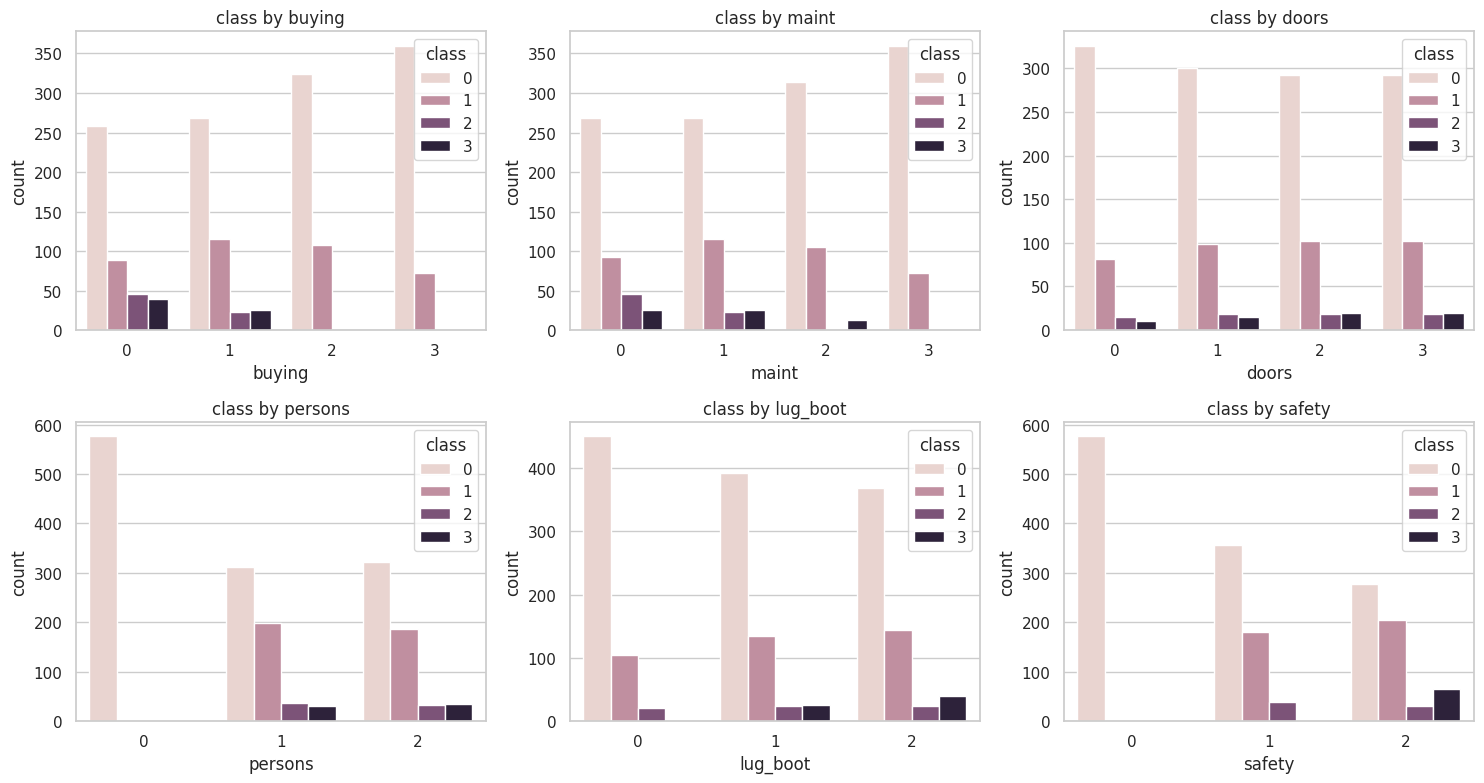

In [64]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
axs = axs.flatten()

for i, col in enumerate(feature_cols):
    sns.countplot(data=df, x=col, hue=target_col, ax=axs[i])
    axs[i].set_title(f"class by {col}")

plt.tight_layout()
plt.show()

**확인 결과**
- **safety = low(0)이면 class 평균 0** → 안전성이 낮으면 무조건 unacc
- **persons = 2(0)이면 class 평균 0** → 2인승이면 무조건 unacc
- buying, maint는 가격이 낮을수록 class 평균이 높음 (싸면 평가가 좋음)
- safety, lug_boot는 클수록 class 평균이 높음
- doors는 클래스 평균 차이가 작음 → 영향이 적음

# 7. 상관관계 분석

In [65]:
target_corr = (
    df.corr()[target_col]
    .drop(target_col)
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

print("class와 상관관계가 높은 변수 순서")
display(target_corr.to_frame("Correlation").round(3))

class와 상관관계가 높은 변수 순서


,Correlation
safety,0.439
persons,0.342
buying,-0.283
maint,-0.232
lug_boot,0.158
doors,0.066


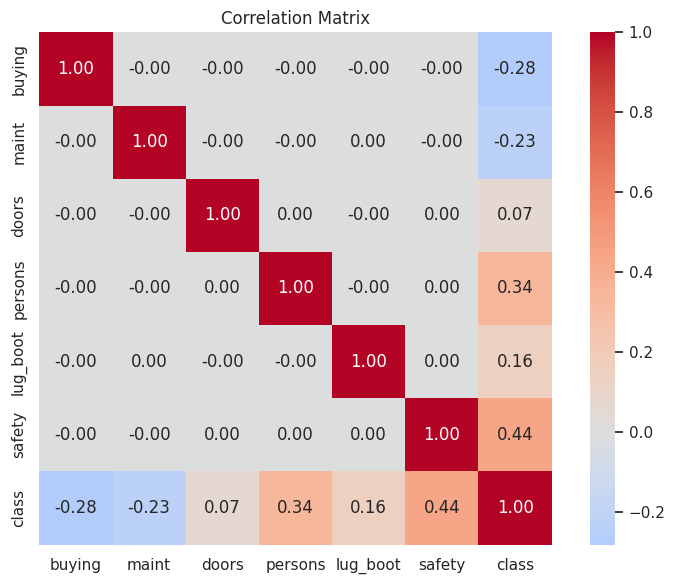

In [66]:
plt.figure(figsize=(8, 6))

sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

**확인 결과**
- class와 상관관계: safety(0.44) > persons(0.34) > buying(-0.28) > maint(-0.23) > lug_boot(0.16) > doors(0.07)
- 입력 변수끼리의 상관관계는 모두 0 → 모든 조합이 한 번씩 들어있는 데이터라서 변수끼리는 서로 독립

# 8. 학습 데이터 준비
- 입력: 6개 변수 전체
- 타깃: class (0 ~ 3 숫자)
- 8:2로 분할 (클래스 불균형이 크므로 stratify로 비율 유지) 후 StandardScaler로 표준화

In [67]:
X = df[feature_cols].values.astype(np.float32)
y = df[target_col].values.astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1382, 6)  Test: (346, 6)


# 9. 평가 지표 (Metric)

In [68]:
results = {}
acc_results = {}

# 10. 기준선 (Baseline): 전부 unacc(0)로 예측
전체의 70%가 unacc이므로, 무조건 0으로만 예측해도 Accuracy가 약 70%가 나온다.
모델은 최소한 이것보다 좋아야 의미가 있다.

In [69]:
baseline_preds = [0] * len(y_test)

mse = mean_squared_error(y_test, baseline_preds)
acc = accuracy_score(y_test, baseline_preds)

results["Baseline (All 0)"] = mse
acc_results["Baseline (All 0)"] = acc

print(f"Baseline MSE: {mse:.4f}, Accuracy: {acc:.4f}")

Baseline MSE: 0.7225, Accuracy: 0.6994


# 11. 기본 회귀 모델 4개 비교

In [70]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": SVR(kernel="linear")
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    mse = mean_squared_error(y_test, preds)
    acc = accuracy_score(y_test, np.round(preds))     # 반올림해서 등급으로 변환

    results[name] = mse
    acc_results[name] = acc

    print(f"{name} MSE: {mse:.4f}, Accuracy: {acc:.4f}")

Linear Regression MSE: 0.3004, Accuracy: 0.6936
Decision Tree MSE: 0.0173, Accuracy: 0.9827
Random Forest MSE: 0.0232, Accuracy: 0.9682
SVR MSE: 0.3275, Accuracy: 0.7457


**확인 결과**
- Decision Tree(98%), Random Forest(97%)는 Accuracy가 매우 높음
- Linear Regression(69%), SVR(75%)은 전부 0으로 찍는 Baseline(70%)과 비슷한 수준
- → class는 "safety가 low면 무조건 unacc"처럼 **규칙(조건)으로 정해지는 값**이라서, 조건으로 나누는 트리 모델은 잘 맞히고, 직선 관계만 찾는 선형 모델은 잘 못 맞힘

# 12. 인공신경망 회귀 모델

In [71]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [72]:
class RegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(6, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)          # 마지막 층: activation 없음
        )

    def forward(self, x):
        return self.model(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RegressionModel().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [73]:
epochs = 100
loss_history = []

model.train()
for epoch in range(epochs):
    total_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        output = model(X_batch)
        loss = criterion(output, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    loss_history.append(total_loss / len(train_loader))

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {total_loss / len(train_loader):.4f}")

Epoch [10/100], Loss: 0.0697
Epoch [20/100], Loss: 0.0487
Epoch [30/100], Loss: 0.0392
Epoch [40/100], Loss: 0.0319
Epoch [50/100], Loss: 0.0249
Epoch [60/100], Loss: 0.0206
Epoch [70/100], Loss: 0.0170
Epoch [80/100], Loss: 0.0154
Epoch [90/100], Loss: 0.0111
Epoch [100/100], Loss: 0.0096


In [74]:
model.eval()
preds, actuals = [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch).cpu().numpy().flatten()
        preds.extend(outputs)
        actuals.extend(y_batch.numpy().flatten())

nn_mse = mean_squared_error(actuals, preds)
nn_acc = accuracy_score(actuals, np.round(preds))     # 반올림해서 등급으로 변환

results["Neural Network"] = nn_mse
acc_results["Neural Network"] = nn_acc

print(f"Neural Network Test MSE: {nn_mse:.4f}")
print(f"Neural Network Test Accuracy: {nn_acc:.4f}")

Neural Network Test MSE: 0.0278
Neural Network Test Accuracy: 0.9827


**확인 결과**
- Test MSE 약 0.03, Accuracy 약 98% (실행할 때마다 조금 달라질 수 있음)
- 선형 모델과 달리 신경망은 ReLU를 거치며 조건(규칙) 같은 관계도 학습할 수 있어서 트리 모델과 비슷한 성능

# 13. 학습 Loss 변화

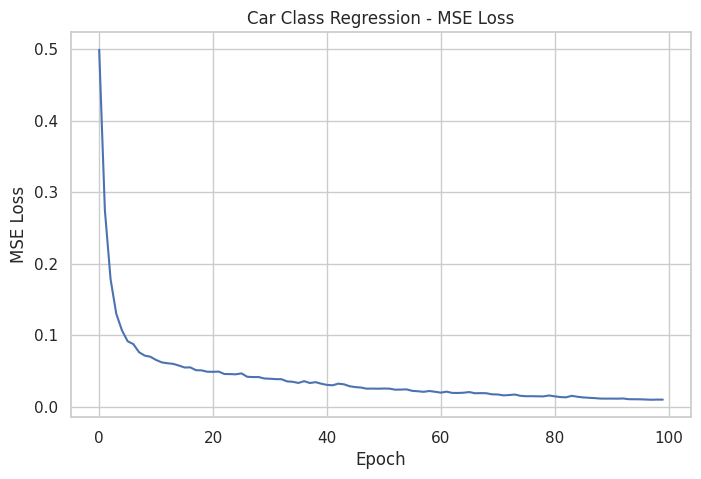

In [75]:
# epoch별 학습 Loss(MSE) 변화 그래프
plt.figure(figsize=(8, 5))

plt.plot(loss_history)                         # x축: epoch, y축: 해당 epoch의 평균 Loss

plt.title("Car Class Regression - MSE Loss")
plt.xlabel("Epoch")                            # 학습 반복 횟수
plt.ylabel("MSE Loss")                         # 작을수록 예측이 정답에 가까움
plt.grid(True)
plt.show()

# 14. 실제값 vs 예측값

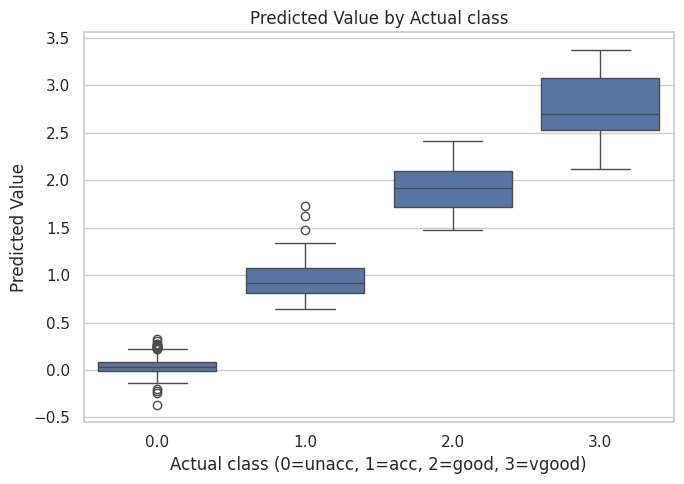

In [76]:
plt.figure(figsize=(7, 5))

sns.boxplot(x=actuals, y=preds)

plt.title("Predicted Value by Actual class")
plt.xlabel("Actual class (0=unacc, 1=acc, 2=good, 3=vgood)")
plt.ylabel("Predicted Value")

plt.tight_layout()
plt.show()

In [77]:
pred_class = np.round(preds)

print("실제 등급별 개수")
print(pd.Series(actuals).value_counts())

print("\n예측 등급(반올림)별 개수")
print(pd.Series(pred_class).value_counts())

print("\n등급별 성능")
print(classification_report(actuals, pred_class))

실제 등급별 개수
0.0    242
1.0     77
2.0     14
3.0     13
Name: count, dtype: int64

예측 등급(반올림)별 개수
0.0    242
1.0     76
2.0     18
3.0     10
Name: count, dtype: int64

등급별 성능
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00       242
         1.0       0.99      0.97      0.98        77
         2.0       0.72      0.93      0.81        14
         3.0       1.00      0.77      0.87        13

    accuracy                           0.98       346
   macro avg       0.93      0.92      0.92       346
weighted avg       0.99      0.98      0.98       346



**확인 결과**
- Box Plot에서 실제 등급(0~3)마다 예측값이 해당 숫자 근처에 모여 있음 → 등급을 잘 구별함
- 예측 등급별 개수도 실제 개수와 거의 같음
- 등급별 성능에서 unacc(0)는 100%, acc(1)·vgood(3)도 90% 이상
- **good(2)가 가장 낮음**: test에 14개뿐이라 데이터가 적고, 1과 3 사이에 있어서 반올림할 때 이웃 등급과 헷갈리기 쉬움
  - precision: 그 등급이라고 예측한 것 중 실제로 맞은 비율
  - recall: 실제 그 등급인 것 중 맞게 찾아낸 비율

# 15. 전체 모델 성능 비교

In [78]:
print("===== 모델별 MSE / Accuracy 비교 (MSE 낮은 순) =====")

for name, mse in sorted(results.items(), key=lambda x: x[1]):
    print(f"{name}: MSE {mse:.4f}, Accuracy {acc_results[name]:.4f}")

best_model = min(results, key=results.get)

print("\nMSE 기준 최적 모델:", best_model)
print(f"최저 MSE: {results[best_model]:.4f}")

===== 모델별 MSE / Accuracy 비교 (MSE 낮은 순) =====
Decision Tree: MSE 0.0173, Accuracy 0.9827
Random Forest: MSE 0.0232, Accuracy 0.9682
Neural Network: MSE 0.0278, Accuracy 0.9827
Linear Regression: MSE 0.3004, Accuracy 0.6936
SVR: MSE 0.3275, Accuracy 0.7457
Baseline (All 0): MSE 0.7225, Accuracy 0.6994

MSE 기준 최적 모델: Decision Tree
최저 MSE: 0.0173


# 16. 결과 분석

### (1) 결과 요약

- MSE 기준 최적 모델은 Decision Tree, 신경망도 비슷하게 약 98%
- 선형 모델(Linear, SVR)은 Baseline(70%)과 비슷해서 거의 학습하지 못함

### (2) 성능이 높은 이유 (트리, 신경망)
1. class가 입력 변수 6개만으로 정해지는 **규칙 기반 데이터** (예: safety가 low이거나 2인승이면 무조건 unacc)
2. 결측치, 중복이 없고 모든 조합이 한 번씩 들어있는 깔끔한 데이터

### (3) 선형 모델의 성능이 낮은 이유
- 선형 모델은 "변수가 커지면 class도 일정하게 커진다"는 직선 관계만 찾을 수 있음
- 이 데이터는 "safety가 low면 다른 값과 상관없이 0" 같은 조건 관계라서 직선으로 표현이 안 됨
- 또 70%가 0이라, 직선으로 대충 맞추면 0 근처 값만 나와서 Baseline과 비슷해짐

### (4) 부족한 점
- **good(2), vgood(3)은 데이터가 각각 4% 정도로 매우 적음** → test에 14개, 13개뿐이라 몇 개만 틀려도 성능이 크게 떨어짐
- 특히 good은 이웃한 acc, vgood과 헷갈리는 경우가 있음
- 전체 Accuracy가 높아도, 70%가 unacc이므로 등급별 성능도 함께 확인해야 함

### (5) 결론
등급을 0~3 숫자로 바꿔 회귀로 예측했을 때, 트리 모델과 신경망은 약 98%의 정확도를 보였다.
데이터가 규칙으로 만들어졌기 때문에 조건 관계를 학습할 수 있는 모델이 잘 맞혔고, 데이터가 적은 good 등급에서 가장 많이 틀렸다.